# RenalInsight — Decision Tree (UCI 336 CKD)

**Author:** Chandresh Singh · BE Data Science (Honours), St. Francis Institute of Technology
**Project:** RenalInsight — An Explainable ML-Based System for Chronic Kidney Disease Prediction and Risk Analysis

This notebook trains a **Decision Tree** classifier on the [UCI 336 Chronic Kidney Disease dataset](https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease) and exports the **4 production artifacts** consumed by the RenalInsight backend:

| Artifact | Purpose |
|---|---|
| `final_model.joblib` | The full fitted scikit-learn `Pipeline` (preprocessing + Decision Tree). |
| `feature_names.joblib` | Transformed feature names, aligned with the SHAP explainer. |
| `shap_explainer.joblib` | Fitted SHAP explainer for per-prediction explanations. |
| `model_metadata.json` | Raw `input_features`, task info, and metrics for the API. |

> **Task type — DIAGNOSIS, not progression.** UCI 336 target `class` (ckd / notckd) is a *current diagnosis* label recorded at the same visit as the lab features. This is **not** a future-progression task.

> **Expect near-perfect accuracy.** The lab features (serum creatinine, albumin, haemoglobin, specific gravity, …) are essentially the clinical criteria used to *assign* the label, so models routinely reach ~99–100% accuracy. That is a property of the dataset (definitional circularity), **not** evidence of a clinically deployable predictor. See §3.

> **One model per notebook.** This is one of five sibling notebooks (Logistic Regression, Random Forest, Decision Tree, SVM, KNN), each identical in structure and each trained on the same preprocessed UCI 336 data. Compare their artifacts / metrics side by side.


In [ ]:
# If running in Google Colab / a fresh environment, install dependencies:
!pip -q install ucimlrepo scikit-learn imbalanced-learn shap joblib matplotlib pandas numpy

In [ ]:
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)
import shap
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries loaded. SHAP version:", shap.__version__)

Libraries loaded. SHAP version: 0.52.0


## 1. Model configuration

This notebook is fixed to **Decision Tree**. The hyper-parameters below are sensible defaults; replace them with the *Best params* your `RenalInsight_Model_Comparison_UCI.ipynb` run reported for this model.


In [ ]:
MODEL_KEY  = 'dtree'
PARAMS     = {'max_depth': 5, 'min_samples_leaf': 2}
OUTPUT_DIR = 'renalinsight_uci_dtree'

def build_classifier(name, params):
    if name == "logreg":
        return LogisticRegression(max_iter=5000, class_weight="balanced",
                                  random_state=RANDOM_STATE, **params)
    if name == "rf":
        return RandomForestClassifier(class_weight="balanced",
                                      random_state=RANDOM_STATE, **params)
    if name == "dtree":
        return DecisionTreeClassifier(class_weight="balanced",
                                      random_state=RANDOM_STATE, **params)
    if name == "svm":
        return SVC(probability=True, class_weight="balanced",
                   random_state=RANDOM_STATE, **params)
    if name == "knn":
        return KNeighborsClassifier(**params)
    raise ValueError("Unknown MODEL_KEY: " + name)

PRETTY = {"logreg": "Logistic Regression", "rf": "Random Forest",
          "dtree": "Decision Tree", "svm": "SVM (RBF)", "knn": "K-Nearest Neighbors"}
final_name = PRETTY[MODEL_KEY]
print("Model      :", final_name)
print("Params     :", PARAMS)
print("Artifacts  :", OUTPUT_DIR)

Model      : Decision Tree
Params     : {'max_depth': 5, 'min_samples_leaf': 2}
Artifacts  : renalinsight_uci_dtree


## 2. Load the UCI 336 dataset

Loaded directly from the UCI ML Repository via `ucimlrepo` (`id=336`). 400 patient records, 24 clinical/lab features, binary target `class` (ckd / notckd).


In [ ]:
from ucimlrepo import fetch_ucirepo

ckd = fetch_ucirepo(id=336)
X_raw = ckd.data.features.copy()
y_raw = ckd.data.targets.copy()

df = X_raw.copy()
TARGET = y_raw.columns[0]           # "class"
df[TARGET] = y_raw[TARGET].values
print("Raw shape:", df.shape)
print("Columns  :", list(df.columns))
df.head()

Raw shape: (400, 25)
Columns  : ['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


### 2.1 Clean the raw data

The UCI 336 export is messy: numeric columns arrive as quoted strings, some values carry stray tab characters (e.g. `'\tno'`, `'ckd\t'`), and missing values appear as `?` or blanks. We normalise strings, coerce numerics, and map the target to `1 = ckd`, `0 = notckd`.


In [ ]:
def clean_str(v):
    """Strip quotes/tabs/whitespace, lower-case, and map blanks/? to NaN."""
    if pd.isna(v):
        return np.nan
    s = str(v).replace("\'", "").replace('"', "").strip().lower()
    return np.nan if s in {"", "?", "nan", "na"} else s

for c in df.columns:
    df[c] = df[c].map(clean_str)

df[TARGET] = df[TARGET].map(lambda s: 1 if isinstance(s, str) and s.startswith("ckd") else
                                       (0 if isinstance(s, str) and s.startswith("notckd") else np.nan))
df = df.dropna(subset=[TARGET])
df[TARGET] = df[TARGET].astype(int)

for c in df.columns:
    if c == TARGET:
        continue
    coerced = pd.to_numeric(df[c], errors="coerce")
    if coerced.notna().sum() >= 0.5 * df[c].notna().sum():
        df[c] = coerced

print("Cleaned shape:", df.shape)
print("Target balance (1=ckd, 0=notckd):")
print(df[TARGET].value_counts())
print("\nPositive rate: %.1f%%" % (100 * df[TARGET].mean()))

Cleaned shape: (400, 25)
Target balance (1=ckd, 0=notckd):
class
1    250
0    150
Name: count, dtype: int64

Positive rate: 62.5%


## 3. Why accuracy will look near-perfect (definitional circularity)

- The lab features in UCI 336 (serum creatinine `sc`, albumin `al`, haemoglobin `hemo`, specific gravity `sg`, packed cell volume `pcv`, …) are **the same measurements clinicians use to assign the CKD label**, so features and target are near-tautologically linked.
- Consequently *every* reasonable model reaches ~99–100% accuracy. High scores demonstrate the code works — **not** real-world predictive skill.
- UCI 336 has **no follow-up / survival columns** (no `TimeToEventMonths`, `TIME_YEAR`, stage, or GFR-category fields), so there is no temporal leakage — but the definitional circularity above is the dominant caveat and is surfaced in the final report and disclaimer.


In [ ]:
def detect_leakage_and_ids(frame, target):
    leak, ids = [], []
    for c in frame.columns:
        if c == target:
            continue
        low = c.lower(); norm = low.replace("_", "").replace(" ", "")
        if any(k in norm for k in ["timetoevent", "followup", "survivalmonth", "months",
                                    "timeyear", "timeyears", "eventtime", "stage", "grf", "affected"]):
            leak.append(c)
        if low in {"id", "patientid", "patient_id", "index", "unnamed: 0"}:
            ids.append(c)
    return leak, ids

leak_cols, id_cols = detect_leakage_and_ids(df, TARGET)
drop_cols = leak_cols + id_cols
print("Leakage columns detected:", leak_cols)
print("ID columns detected     :", id_cols)

df_model = df.drop(columns=drop_cols) if drop_cols else df.copy()
feature_cols = [c for c in df_model.columns if c != TARGET]
print("\nPredictors used (%d):" % len(feature_cols), feature_cols)

Leakage columns detected: []
ID columns detected     : []

Predictors used (24): ['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


### 3.1 Feature reference (UCI 336)

| Code | Meaning | | Code | Meaning |
|---|---|---|---|---|
| age | Age (years) | | pcv | Packed cell volume |
| bp | Blood pressure (mm Hg) | | wbcc | White blood cell count |
| sg | Specific gravity | | rbcc | Red blood cell count |
| al | Albumin (0–5) | | htn | Hypertension (yes/no) |
| su | Sugar (0–5) | | dm | Diabetes mellitus (yes/no) |
| rbc | Red blood cells (normal/abnormal) | | cad | Coronary artery disease |
| pc | Pus cell (normal/abnormal) | | appet | Appetite (good/poor) |
| pcc | Pus cell clumps | | pe | Pedal edema (yes/no) |
| ba | Bacteria | | ane | Anaemia (yes/no) |
| bgr | Blood glucose random | | sc | Serum creatinine |
| bu | Blood urea | | sod | Sodium |
| hemo | Haemoglobin | | pot | Potassium |

> Numeric vs. categorical columns are detected **at runtime**, so the notebook adapts if a copy of the data differs slightly.


## 4. Train / test split

An 80/20 stratified split. The test set is held out and **never** touched during training or preprocessing fitting.


In [ ]:
X = df_model[feature_cols].copy()
y = df_model[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train positive rate: %.1f%%" % (100 * y_train.mean()))
print("Test  positive rate: %.1f%%" % (100 * y_test.mean()))

Train: (320, 24)  Test: (80, 24)
Train positive rate: 62.5%
Test  positive rate: 62.5%


## 5. Preprocessing

Numeric columns: median imputation + standard scaling. Categorical columns: most-frequent imputation + one-hot encoding. Fitted **only on the training set** inside the pipeline.


In [ ]:
num_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(X_train[c])]
cat_cols = [c for c in feature_cols if c not in num_cols]
print("Numeric   (%d):" % len(num_cols), num_cols)
print("Categorical (%d):" % len(cat_cols), cat_cols)

numeric_tf = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("scaler", StandardScaler())])
categorical_tf = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", numeric_tf, num_cols),
    ("cat", categorical_tf, cat_cols),
])
preprocessor

Numeric   (14): ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
Categorical (10): ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu',
                                  'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc',
                                  'rbcc']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad',
                                  'appet', 'pe', 'ane'])])

## 6. Build and train the pipeline

The UCI 336 target is only mildly imbalanced (~62% ckd), so we rely on `class_weight="balanced"` (where supported) rather than SMOTE. The pipeline is `preprocessor → classifier`, fitted on the training set only.


In [ ]:
final_clf = build_classifier(MODEL_KEY, PARAMS)

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", final_clf),
])

final_model.fit(X_train, y_train)
print("Trained:", final_name)
final_model

Trained: Decision Tree


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bp', 'sg', 'al',
                                                   'su', 'bgr', 'bu', 'sc',
                                                   'sod', 'pot', 'hemo', 'pcv',
                                                   'wbcc', 'rbcc']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['rbc', 'pc', 'pcc', 'ba',
                                                   'htn', 'dm', 'cad', 'appet',
                                                   'pe', 'ane'])])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                                        min_samples_leaf=2, random_state=42))])

## 7. Evaluate on the held-out test set

Reported metrics: accuracy, precision, recall (sensitivity), specificity, F1, ROC-AUC, PR-AUC, and the confusion matrix.


In [ ]:
y_pred = final_model.predict(X_test)
if hasattr(final_model, "predict_proba"):
    y_score = final_model.predict_proba(X_test)[:, 1]
else:
    y_score = final_model.decision_function(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp) if (tn + fp) else 0.0

test_metrics = {
    "Accuracy":            round(accuracy_score(y_test, y_pred), 4),
    "Precision":           round(precision_score(y_test, y_pred, zero_division=0), 4),
    "Recall (Sensitivity)": round(recall_score(y_test, y_pred, zero_division=0), 4),
    "Specificity":         round(specificity, 4),
    "F1":                  round(f1_score(y_test, y_pred, zero_division=0), 4),
    "ROC-AUC":             round(roc_auc_score(y_test, y_score), 4),
    "PR-AUC":              round(average_precision_score(y_test, y_score), 4),
}
print("Test metrics for %s:" % final_name)
for k, v in test_metrics.items():
    print(f"  {k:20s}: {v}")
print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=["notckd", "ckd"]))

Test metrics for Decision Tree:
  Accuracy            : 0.9625
  Precision           : 1.0
  Recall (Sensitivity): 0.94
  Specificity         : 1.0
  F1                  : 0.9691
  ROC-AUC             : 0.989
  PR-AUC              : 0.9917

Confusion matrix [[TN, FP], [FN, TP]]:
[[30  0]
 [ 3 47]]

               precision    recall  f1-score   support

      notckd       0.91      1.00      0.95        30
         ckd       1.00      0.94      0.97        50

    accuracy                           0.96        80
   macro avg       0.95      0.97      0.96        80
weighted avg       0.97      0.96      0.96        80



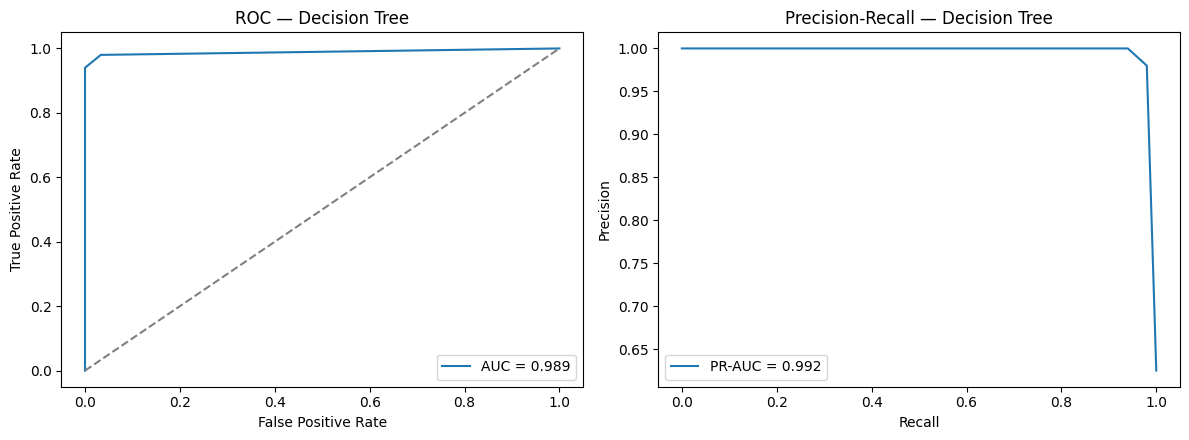

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
fpr, tpr, _ = roc_curve(y_test, y_score)
ax[0].plot(fpr, tpr, label="AUC = %.3f" % test_metrics["ROC-AUC"])
ax[0].plot([0, 1], [0, 1], "--", color="grey")
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC — %s" % final_name); ax[0].legend()

prec, rec, _ = precision_recall_curve(y_test, y_score)
ax[1].plot(rec, prec, label="PR-AUC = %.3f" % test_metrics["PR-AUC"])
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall — %s" % final_name); ax[1].legend()
plt.tight_layout(); plt.show()

> **Reminder:** near-perfect scores here reflect the definitional circularity described in §3, not real-world predictive skill. Report them with that caveat.

## 8. SHAP explainer

Built on the **already-fitted** preprocessor output (no refit, no leakage). The explainer type matches the model family: `LinearExplainer` (Logistic Regression), `TreeExplainer` (Random Forest / Decision Tree), or the model-agnostic `Explainer` (SVM / KNN).


In [ ]:
X_train_pre = final_model.named_steps["preprocessor"].transform(X_train)
try:
    feature_names = list(final_model.named_steps["preprocessor"].get_feature_names_out())
except Exception:
    feature_names = [f"f{i}" for i in range(X_train_pre.shape[1])]

fitted_clf = final_model.named_steps["model"]
bg = shap.utils.sample(X_train_pre, min(100, X_train_pre.shape[0]), random_state=RANDOM_STATE)

if MODEL_KEY == "logreg":
    explainer = shap.LinearExplainer(fitted_clf, X_train_pre)
elif MODEL_KEY in ("rf", "dtree"):
    explainer = shap.TreeExplainer(fitted_clf)
else:  # svm, knn -> model-agnostic
    predict_fn = (fitted_clf.predict_proba if hasattr(fitted_clf, "predict_proba")
                  else fitted_clf.decision_function)
    explainer = shap.Explainer(predict_fn, bg)

def pos_class_values(shap_values):
    """Return 2-D (n, features) SHAP values for the positive class, whatever
    the explainer's raw output shape (handles the SVM/KNN (n, feats, 2) case)."""
    v = np.asarray(shap_values.values)
    if v.ndim == 3:
        v = v[:, :, -1]
    return v

print("SHAP explainer:", type(explainer).__name__)
print("Transformed feature count:", len(feature_names))

SHAP explainer: TreeExplainer
Transformed feature count: 34


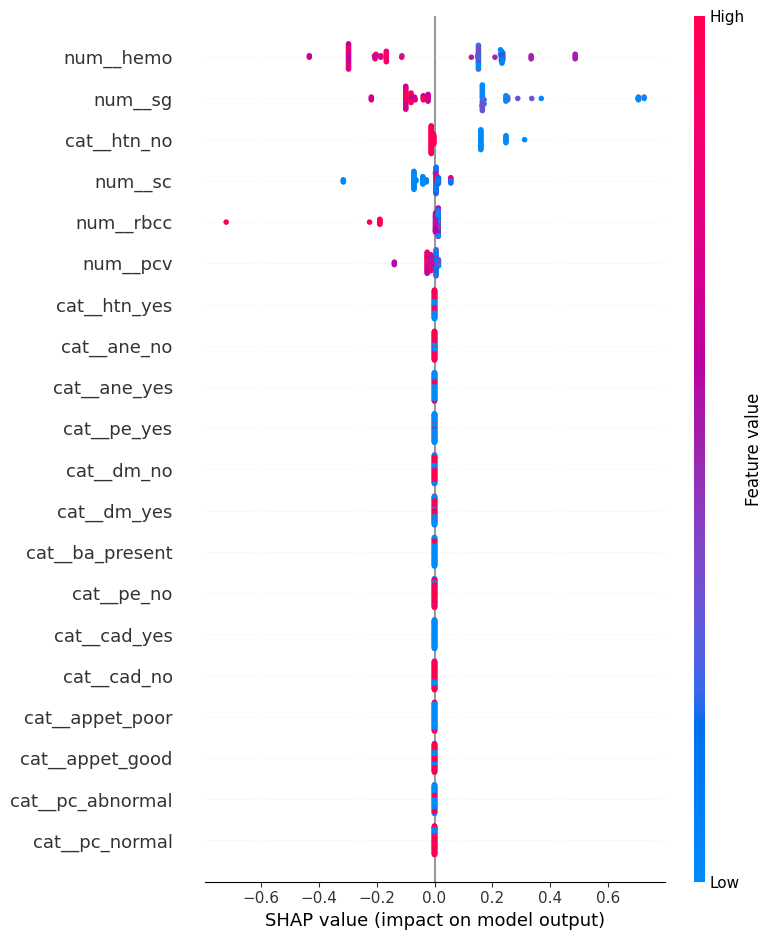

In [ ]:
X_test_pre = final_model.named_steps["preprocessor"].transform(X_test)
sample_n = min(100, X_test_pre.shape[0])
try:
    sv = explainer(X_test_pre[:sample_n])
    shap.summary_plot(pos_class_values(sv), features=X_test_pre[:sample_n],
                      feature_names=feature_names, show=True)
except Exception as e:
    print("SHAP summary skipped:", e)

## 9. Single-prediction helper (matches the backend contract)

The API sends a dict of **raw** feature values (keyed by the original UCI codes). This helper builds a one-row DataFrame, runs the pipeline, and returns the probability plus per-feature SHAP contributions.


In [ ]:
def explain_one(raw_dict):
    """raw_dict: {feature_code: value} using original UCI 336 columns."""
    row = pd.DataFrame([{c: raw_dict.get(c, np.nan) for c in feature_cols}])
    proba = float(final_model.predict_proba(row)[0, 1]) if hasattr(final_model, "predict_proba") \
            else float(final_model.decision_function(row)[0])
    row_pre = final_model.named_steps["preprocessor"].transform(row)
    contribs = {}
    try:
        sv1 = explainer(row_pre)
        vals = pos_class_values(sv1).reshape(-1)
        contribs = dict(sorted(zip(feature_names, vals.tolist()),
                               key=lambda kv: abs(kv[1]), reverse=True)[:10])
    except Exception as e:
        contribs = {"_error": str(e)}
    return {"ckd_probability": proba, "prediction": int(proba >= 0.5), "top_shap": contribs}

demo = X_test.iloc[0].to_dict()
print("Demo prediction:", json.dumps(explain_one(demo), indent=2, default=str))

Demo prediction: {
  "ckd_probability": 0.0,
  "prediction": 0,
  "top_shap": {
    "num__rbcc": -0.18861381673881583,
    "num__hemo": -0.1662725947832554,
    "num__sg": -0.080799338224845,
    "num__sc": -0.04026594065656531,
    "num__pcv": -0.012689957611832564,
    "cat__htn_no": -0.011358351984683407,
    "cat__htn_yes": -9.71445146547012e-17,
    "cat__ane_no": 5.204170427930421e-18,
    "num__age": 0.0,
    "num__bp": 0.0
  }
}


## 10. Export the 4 production artifacts

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(final_model,   os.path.join(OUTPUT_DIR, "final_model.joblib"))
joblib.dump(feature_names, os.path.join(OUTPUT_DIR, "feature_names.joblib"))
joblib.dump(explainer,     os.path.join(OUTPUT_DIR, "shap_explainer.joblib"))

metadata = {
    "project": "RenalInsight",
    "dataset": "UCI 336 Chronic Kidney Disease",
    "task": "diagnosis (ckd vs notckd) — NOT future progression",
    "final_model": final_name,
    "model_key": MODEL_KEY,
    "best_params": PARAMS,
    "target": TARGET,
    "positive_label": "ckd = 1",
    "input_features": feature_cols,
    "numeric_features": num_cols,
    "categorical_features": cat_cols,
    "transformed_feature_count": len(feature_names),
    "excluded_leakage": leak_cols,
    "excluded_ids": id_cols,
    "test_metrics": test_metrics,
    "random_state": RANDOM_STATE,
    "caveat": ("Near-perfect accuracy reflects definitional circularity in UCI 336 "
               "(lab features are the diagnostic criteria), not real-world predictive skill."),
}
with open(os.path.join(OUTPUT_DIR, "model_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Artifacts written to", OUTPUT_DIR, ":")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print("  ", fn)

Artifacts written to renalinsight_uci_dtree :
   feature_names.joblib
   final_model.joblib
   model_metadata.json
   shap_explainer.joblib


In [ ]:
import shutil
zip_base = OUTPUT_DIR + "_artifacts"
shutil.make_archive(zip_base, "zip", OUTPUT_DIR)
print("Zipped:", zip_base + ".zip")
try:
    from google.colab import files; files.download(zip_base + ".zip")
except Exception:
    print("(Not on Colab — download the zip from the file browser.)")

Zipped: renalinsight_uci_dtree_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Backend integration notes

- Load with `joblib.load("final_model.joblib")` and call `predict` / `predict_proba` on a DataFrame whose columns are exactly `model_metadata.json["input_features"]` (the raw UCI codes, e.g. `age`, `bp`, `sc`, `hemo`, …).
- Missing values are handled by the pipeline's imputers, so the API may pass `NaN` for absent fields.
- Use `feature_names.joblib` to label SHAP contributions in the UI; they align with the transformed matrix the explainer sees.
- Do **not** hardcode any credentials, file paths, or secrets in the backend — load artifacts from a configured directory.

### Medical disclaimer
RenalInsight is a **research / educational** project. UCI 336 is a diagnosis dataset with definitional circularity between its features and label; the model's high accuracy does **not** imply clinical validity. Outputs must not be used for diagnosis, treatment, or any real medical decision. Always consult a qualified nephrologist.
